# Market Basket Analysis for Online Retail Product Recommendations

Teresa Ferrill — DSC 680, Project 2, Milestone 2

Question: Can product association rules recover hidden products in later baskets better than a popular-product baseline? This analyzes invoices rather than the customer clusters in the earlier portfolio project.

Run all cells from this project directory. Install requirements first.

## Method and alternatives
FP-growth fits co-purchase data without assuming a purchase sequence. Pair rules limit computational cost and aid interpretation. A popularity baseline tests whether the additional complexity helps. Collaborative filtering is a possible extension; customer clustering addresses a different question.

Chronological development, validation, and test periods prevent future transactions entering rule selection. Candidate products and popularity ranks come only from fitting data. The test basket retains all eligible products, including unseen targets.

## Setup

Install dependencies into the notebook’s active Python environment before running the analysis. Run the appropriate command in a temporary code cell:

- If the working directory is `notebook/`: `%pip install -r ../requirements.txt`
- If the working directory is the repository root: `%pip install -r requirements.txt`

Use `Path.cwd()` to check the working directory. Restart the kernel after installation, then run all cells. The analysis cell locates the repository root from either location.


In [1]:
import sys
import mlxtend
from mlxtend.frequent_patterns import fpgrowth, association_rules

print("Python version:", sys.version.split()[0])
print("mlxtend version:", mlxtend.__version__)

Python version: 3.13.9
mlxtend version: 0.25.0


In [2]:
from pathlib import Path
import runpy

# Locate the repository root whether Jupyter starts
# in the root folder or the notebook folder.
current = Path.cwd().resolve()

project = next(
    (
        folder
        for folder in (current, *current.parents)
        if (folder / "requirements.txt").is_file()
        and (folder / "data").is_dir()
        and (folder / "notebook").is_dir()
    ),
    None,
)

if project is None:
    raise FileNotFoundError(
        "Cannot locate the Market-Basket-Analysis repository root."
    )

script = project / "analysis.py"

if not script.is_file():
    raise FileNotFoundError(
        f"Upload analysis.py to the repository root: {script}"
    )

from time import perf_counter

print("Project folder:", project)
print("Running analysis—please wait...", flush=True)

start = perf_counter()
analysis = runpy.run_path(str(script))

print(
    f"Analysis completed in "
    f"{(perf_counter() - start) / 60:.2f} minutes."
)

Project folder: C:\Users\ferri\anaconda_projects\DSC680\TermProject_2\Milestone_2\Market_Basket_Analysis_Package\retail_project
Running analysis—please wait...
{
  "raw_rows": 541909,
  "clean_rows": 522504,
  "missing_customer_rows_retained": 131354,
  "baskets": 19773,
  "products": 3900,
  "train_baskets": 11044,
  "validation_baskets": 3157,
  "test_baskets": 5572,
  "eligible_test_baskets": 5183,
  "chosen_support": 0.005,
  "chosen_lift": 1.5,
  "rules": 10842,
  "rule_hit_at_5": 0.09839861084314104,
  "baseline_hit_at_5": 0.020065599073895428,
  "coverage": 0.901601389156859,
  "unseen_targets": 340,
  "difference_ci95": [
    0.07003665830600038,
    0.08643642677985723
  ],
  "min_date": "2010-12-01 08:26:00",
  "max_date": "2011-12-09 12:50:00"
}
Analysis completed in 2.60 minutes.


## Results and interpretation
Hit rate at 5 counts all eligible baskets, including those with no rule recommendation. Coverage is the proportion receiving at least one rule recommendation. The paired bootstrap interval describes uncertainty in the observed basket sample; repeated customers and seasonal dependence limit its interpretation.

In [3]:
import pandas as pd
import json

summary = json.loads(
    (project / "results" / "summary.json").read_text()
)

summary

{'raw_rows': 541909,
 'clean_rows': 522504,
 'missing_customer_rows_retained': 131354,
 'baskets': 19773,
 'products': 3900,
 'train_baskets': 11044,
 'validation_baskets': 3157,
 'test_baskets': 5572,
 'eligible_test_baskets': 5183,
 'chosen_support': 0.005,
 'chosen_lift': 1.5,
 'rules': 10842,
 'rule_hit_at_5': 0.09839861084314104,
 'baseline_hit_at_5': 0.020065599073895428,
 'coverage': 0.901601389156859,
 'unseen_targets': 340,
 'difference_ci95': [0.07003665830600038, 0.08643642677985723],
 'min_date': '2010-12-01 08:26:00',
 'max_date': '2011-12-09 12:50:00'}

In [4]:
pd.read_csv(project/'results/cleaning_audit.csv')

,step,removed_rows
0,Missing invoice product or date,0
1,Cancellation invoice,9288
2,Nonpositive or missing quantity or price,2517
3,Nonmerchandise or atypical product code,2379
4,Exact duplicate row,5221


In [5]:
pd.read_csv(project/'results/validation.csv')

,support,lift,rules,hit_rate,coverage,baseline
0,0.005,1.5,10982,0.120924,0.911345,0.030571
1,0.005,1.0,11154,0.120584,0.911345,0.030571
2,0.005,2.0,9970,0.120584,0.909986,0.030571
3,0.010,1.5,1742,0.117188,0.863451,0.030571
4,0.010,1.0,1758,0.116848,0.863451,0.030571
5,0.010,2.0,1616,0.116168,0.863451,0.030571


### Validation Results and Model Selection

The six candidate settings compare minimum support of 0.5% or 1% and minimum lift of 1, 1.5, or 2. The combination of **0.5% support and 1.5 lift** achieved the highest validation hit rate at five recommendations: **12.09%**, with **91.13% coverage**. The validation popularity baseline achieved **3.06%**.

This setting was selected using validation results, then refitted on all invoices before October 2011. The final test period was reserved for evaluation. The small differences between candidate settings do not establish that this setting is universally optimal.


In [6]:
pd.read_csv(project/'results/rules.csv').head(15)

,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski,a,b,antecedent_name,consequent_name
0,0.021407,0.021829,0.015844,0.740132,33.905189,1.0,0.015377,3.764099,0.991736,0.578406,0.734332,0.732969,22745,22748,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE KITCHEN
1,0.021829,0.021407,0.015844,0.725806,33.905189,1.0,0.015377,3.568986,0.992164,0.578406,0.719808,0.732969,22748,22745,POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE BEDROOM
2,0.022534,0.026618,0.018168,0.806250,30.289831,1.0,0.017568,5.023908,0.989278,0.586364,0.800952,0.744395,84596F,84596B,SMALL MARSHMALLOWS PINK BOWL,SMALL DOLLY MIX DESIGN ORANGE BOWL
3,0.026618,0.022534,0.018168,0.682540,30.289831,1.0,0.017568,3.079019,0.993429,0.586364,0.675221,0.744395,84596B,84596F,SMALL DOLLY MIX DESIGN ORANGE BOWL,SMALL MARSHMALLOWS PINK BOWL
4,0.023097,0.023027,0.015633,0.676829,29.393433,1.0,0.015101,3.023088,0.988817,0.512702,0.669212,0.677864,47590B,47590A,PINK HAPPY BIRTHDAY BUNTING,BLUE HAPPY BIRTHDAY BUNTING
5,0.023027,0.023097,0.015633,0.678899,29.393433,1.0,0.015101,3.042355,0.988746,0.512702,0.671307,0.677864,47590A,47590B,BLUE HAPPY BIRTHDAY BUNTING,PINK HAPPY BIRTHDAY BUNTING
6,0.020914,0.021407,0.012182,0.582492,27.210404,1.0,0.011735,2.343888,0.983825,0.404206,0.573358,0.575785,21671,21670,RED SPOT CERAMIC DRAWER KNOB,BLUE SPOT CERAMIC DRAWER KNOB
7,0.021407,0.020914,0.012182,0.569079,27.210404,1.0,0.011735,2.272077,0.984321,0.404206,0.559874,0.575785,21670,21671,BLUE SPOT CERAMIC DRAWER KNOB,RED SPOT CERAMIC DRAWER KNOB
8,0.022604,0.020210,0.012323,0.545171,26.975534,1.0,0.011866,2.154196,0.985199,0.404157,0.535790,0.577464,23321,23322,SMALL WHITE HEART OF WICKER,LARGE WHITE HEART OF WICKER
9,0.020210,0.022604,0.012323,0.609756,26.975534,1.0,0.011866,2.504577,0.982791,0.404157,0.600731,0.577464,23322,23321,LARGE WHITE HEART OF WICKER,SMALL WHITE HEART OF WICKER


### Interpreting a Product Association

One rule links **POPPY’S PLAYHOUSE BEDROOM** to **POPPY’S PLAYHOUSE KITCHEN**. Its support is approximately **1.58%**, confidence is **74.01%**, and lift is **33.91**.

- Support means both products appear together in approximately 1.58% of the development baskets used to fit the final rules.
- Confidence means approximately 74.01% of those baskets containing the bedroom product also contain the kitchen product.
- Lift means that conditional co-purchase rate is about 33.91 times the kitchen product’s overall basket prevalence.

The pairing is a candidate for merchandising review because the products belong to the same range. High lift alone does not imply broad applicability, customer acceptance, or an increase in sales. These rule statistics describe development data, not final-test accuracy.


### Presentation chart formatting

The following cell regenerates Figure 4 from the saved final-test metrics with a percentage axis and larger bar labels for Slide 9. It changes presentation formatting only. Run it after the summary cell and before displaying the figures; rerun it whenever analysis.py regenerates the original charts.


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Use the existing final-test metrics; no model refitting is needed here.
labels = ["Association rules", "Popular products"]
rates = [100 * summary["rule_hit_at_5"], 100 * summary["baseline_hit_at_5"]]

fig, ax = plt.subplots(figsize=(9, 5), dpi=200)
bars = ax.bar(labels, rates, width=0.55, color=["#00858B", "#C17F28"])
ax.set_ylabel("Hidden products recovered (%)", fontsize=16, labelpad=12)
ax.set_ylim(0, max(rates) * 1.25)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.tick_params(axis="both", labelsize=14)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.20)
ax.spines[["top", "right"]].set_visible(False)
ax.bar_label(bars, labels=[f"{value:.2f}%" for value in rates],
             padding=8, fontsize=20, fontweight="bold")
fig.tight_layout()
chart_path = project / "results" / "04_recommendation_performance.png"
fig.savefig(chart_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.close(fig)


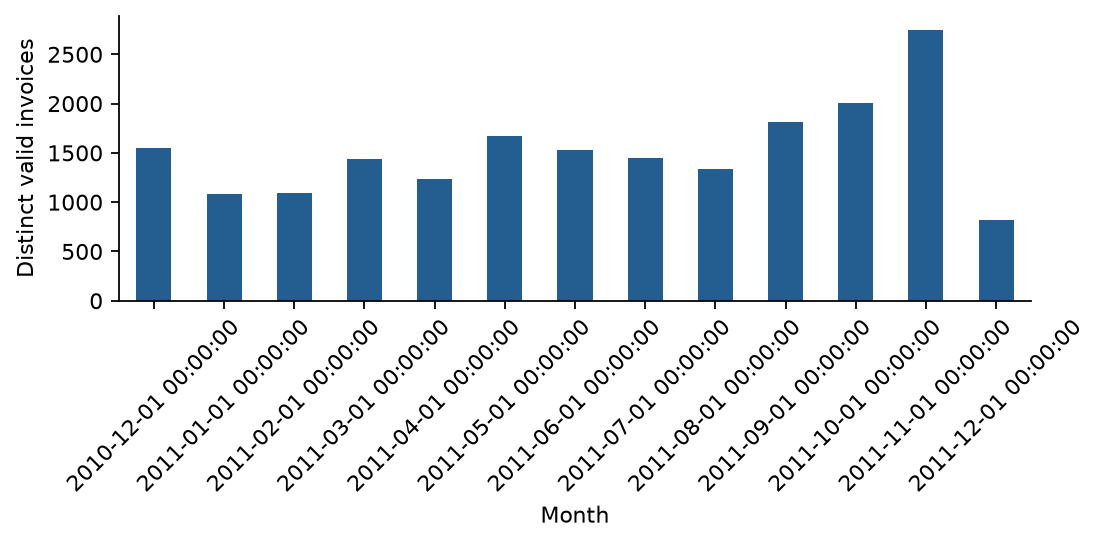

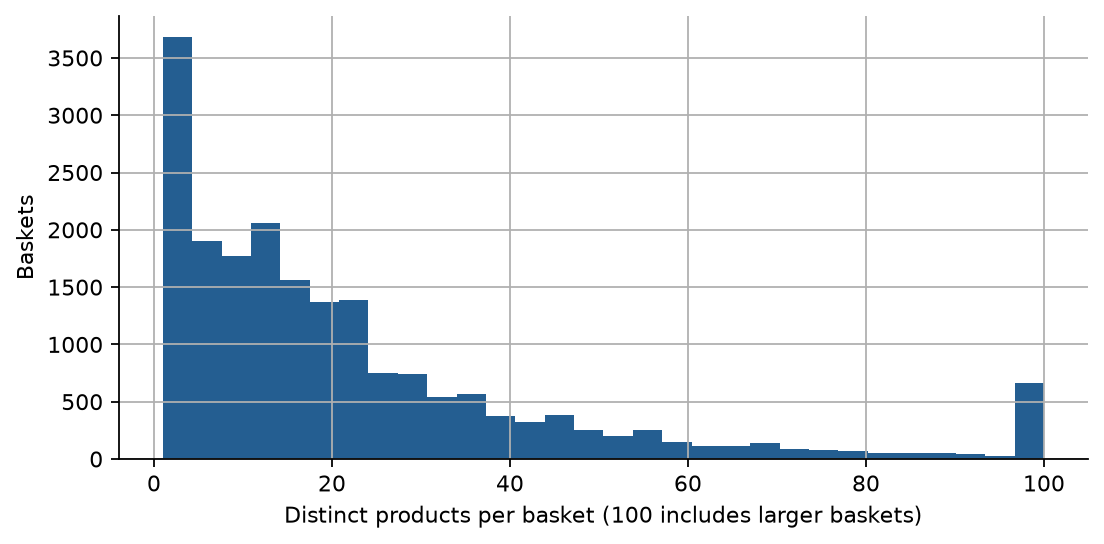

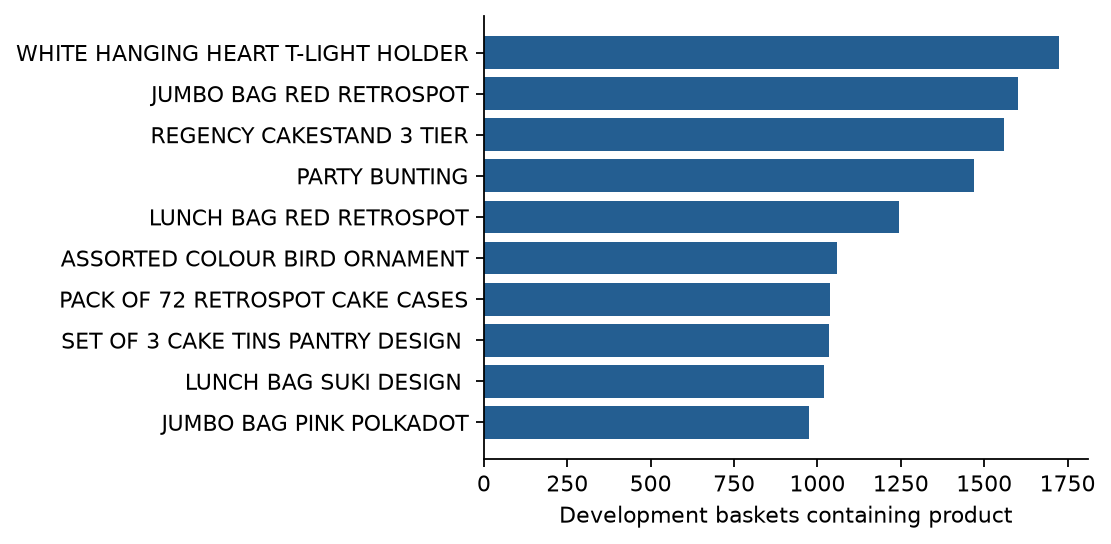

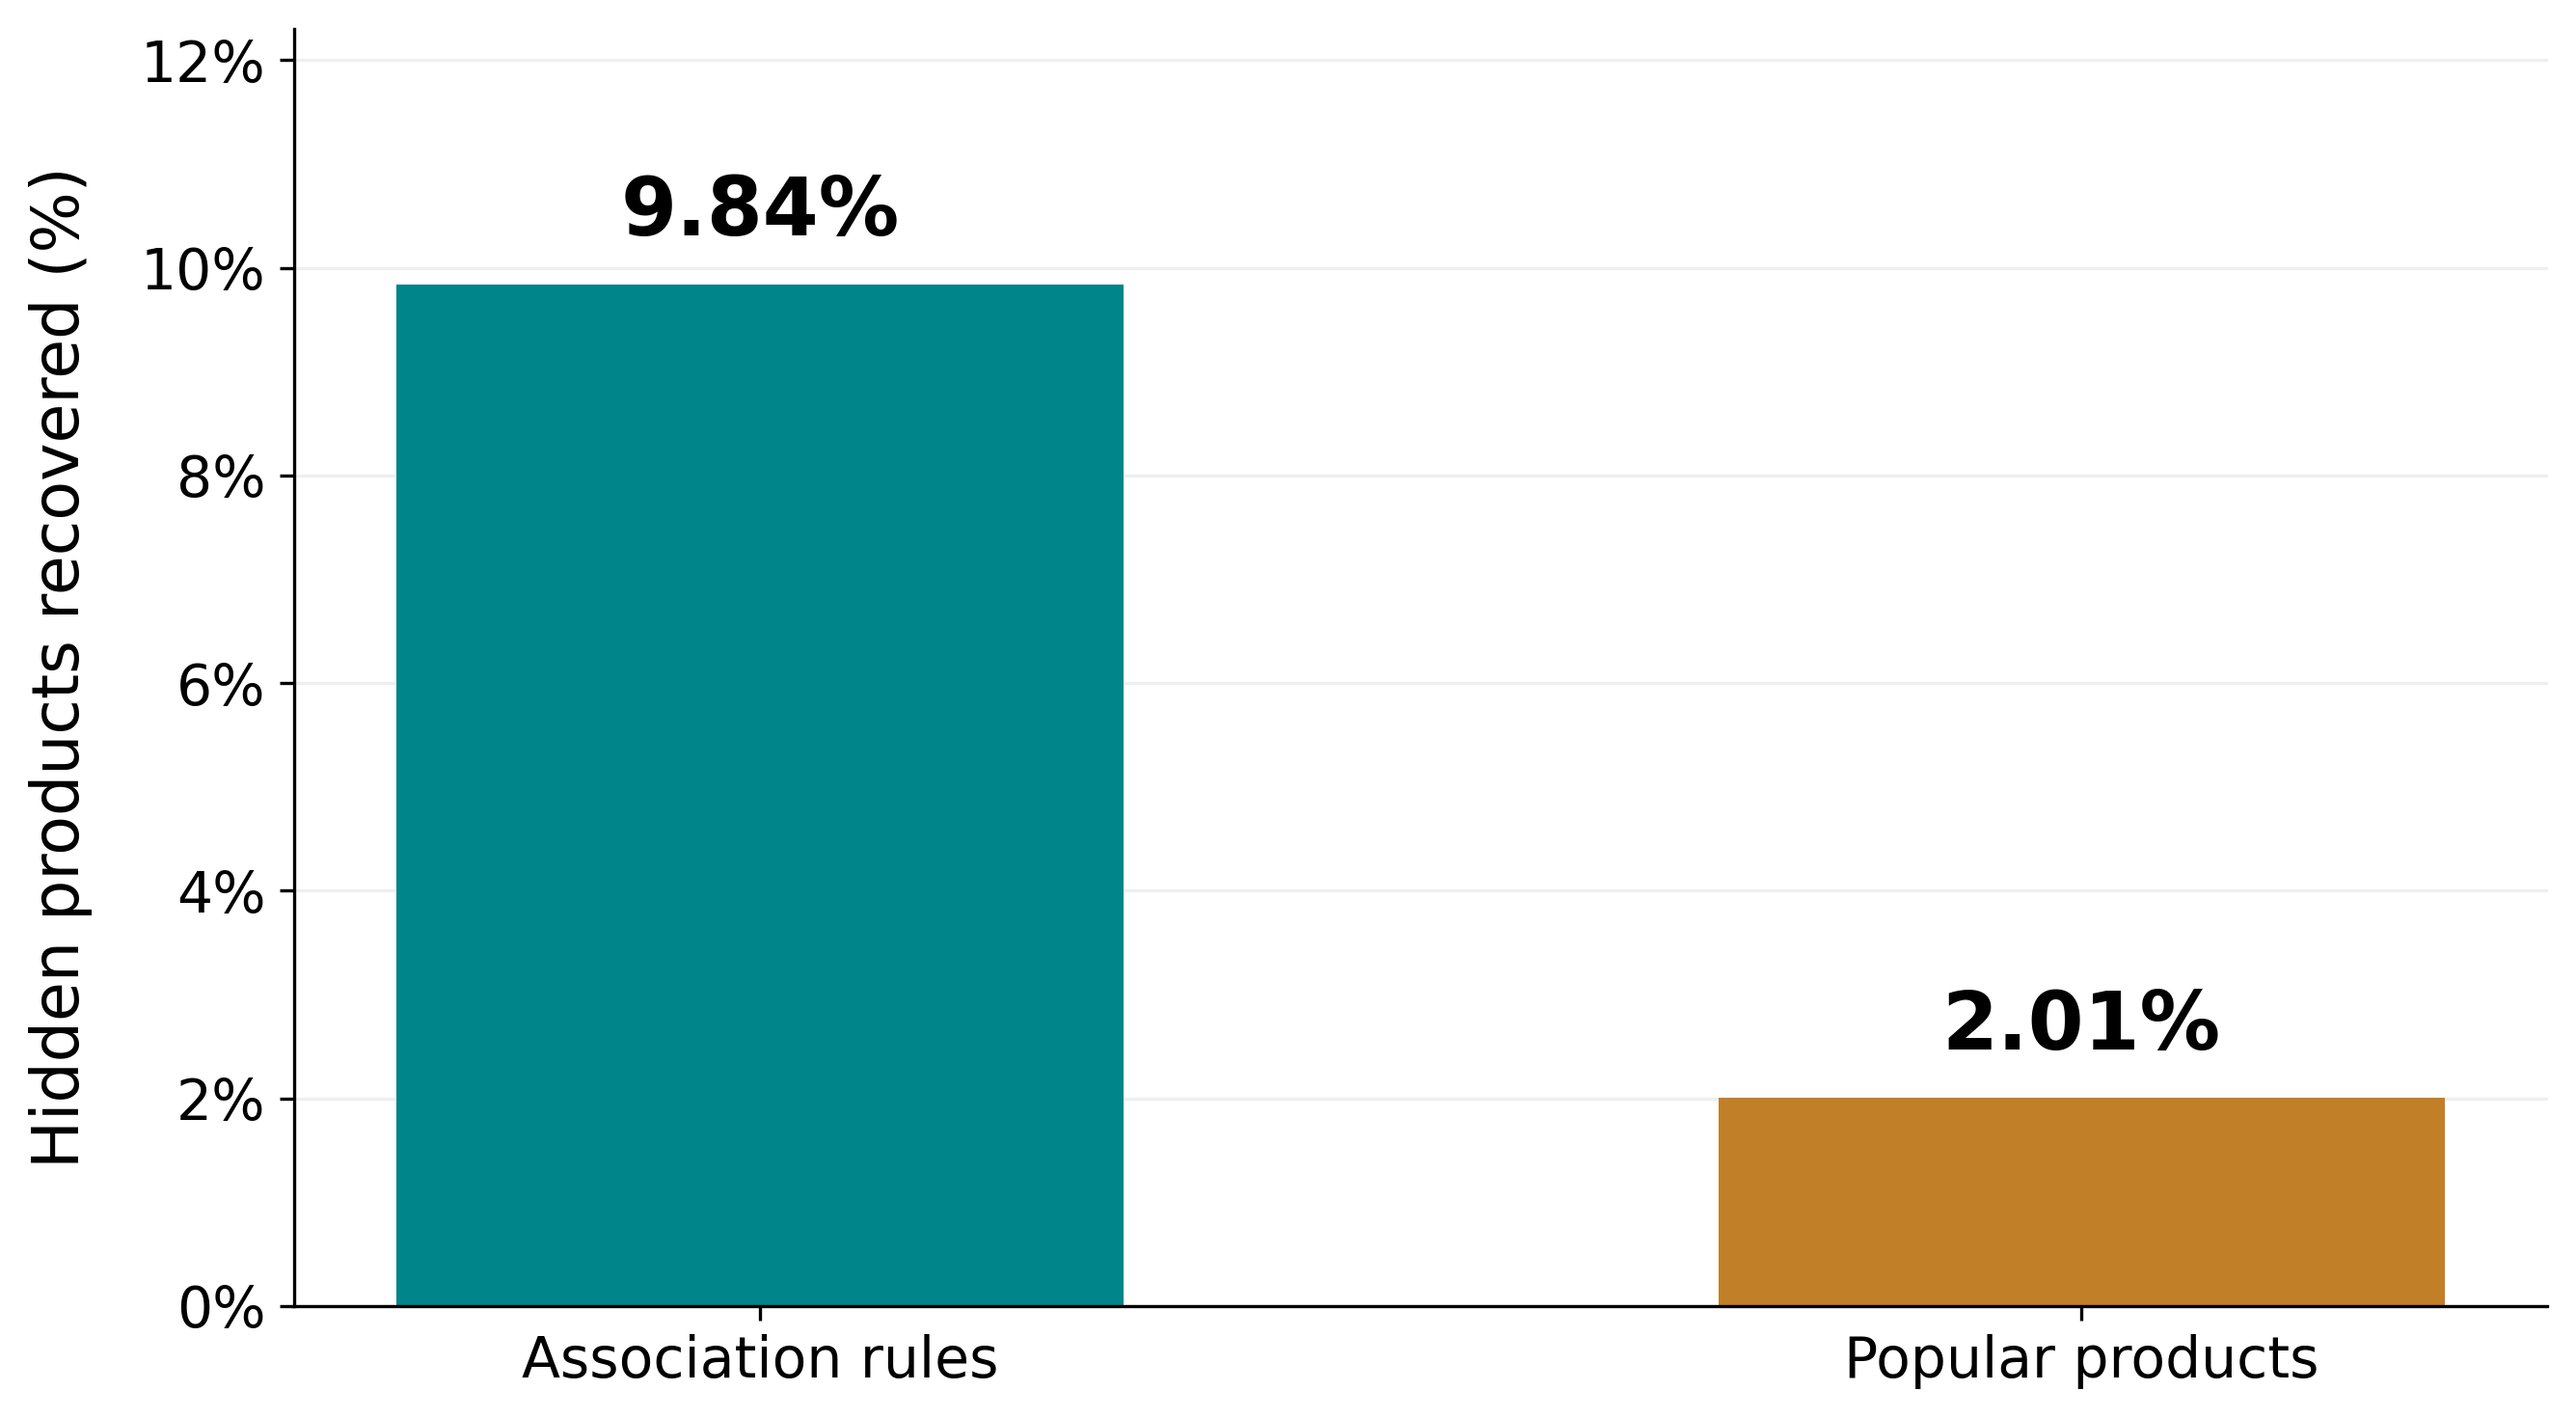

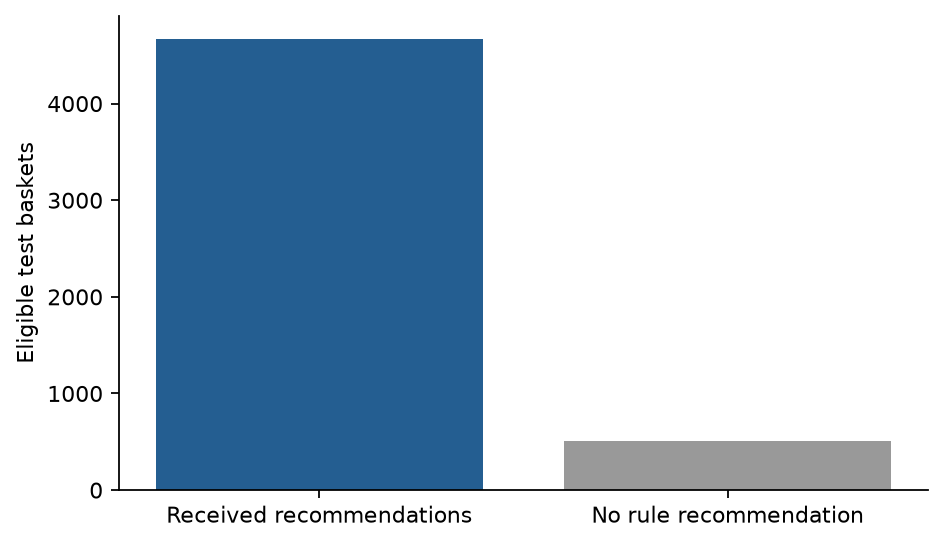

In [7]:
from IPython.display import display, Image
for chart in sorted((project/'results').glob('*.png')):
    display(Image(filename=str(chart)))

### Final Test Findings and Business Recommendation

Across **5,183 eligible test baskets**, association rules recovered the hidden item among up to five recommendations in **9.84%** of baskets. The popular-product baseline recovered it in **2.01%**, an improvement of **7.83 percentage points**. Baskets receiving no rule recommendation remain in the denominator as misses.

**Coverage of 90.16% is not accuracy:** it means the system could produce at least one recommendation for that percentage of eligible baskets. Most hidden products were still not recovered. The evaluation retained **340 targets unseen during development**, reflecting one limitation of recommending products from historical relationships.

The paired basket bootstrap gives an approximate 95% interval of **7.00–8.64 percentage points** for the observed improvement. Repeated customers and temporal dependence limit this uncertainty estimate. The final period also includes seasonal demand and an incomplete December.

I recommend reviewing suitable product pairings, checking current inventory, and testing recommendations in a limited pilot. A popularity fallback could serve baskets without matching rules, but that combined policy has not been evaluated here. A controlled business test would be needed before claiming increased conversion or revenue. These results concern offline basket completion, not next-purchase prediction or causal sales gains.


## Record the Execution Environment

The following cell records the active kernel’s Python and package versions in `environment_versions.json` at the repository root. Commit this file alongside the notebook after a successful complete run.


In [8]:
import sys
import json
from importlib.metadata import version

packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "openpyxl",
    "mlxtend",
    "scikit-learn",
]

versions = {
    "python": sys.version.split()[0],
    **{package: version(package) for package in packages},
}

output_path = project / "environment_versions.json"

output_path.write_text(
    json.dumps(versions, indent=2),
    encoding="utf-8",
)

print(f"Saved: {output_path}")
print(json.dumps(versions, indent=2))

Saved: C:\Users\ferri\anaconda_projects\DSC680\TermProject_2\Milestone_2\Market_Basket_Analysis_Package\retail_project\environment_versions.json
{
  "python": "3.13.9",
  "pandas": "2.3.3",
  "numpy": "2.3.5",
  "matplotlib": "3.11.2",
  "openpyxl": "3.1.5",
  "mlxtend": "0.25.0",
  "scikit-learn": "1.9.1"
}


## Ethics and limitations
Customer identifiers are unnecessary and are not used for recommendations. Exclusions and missing customer records are documented. Standard merchandise-code filtering may exclude unusual legitimate items. Wholesale baskets, seasonal changes, and popularity affect representativeness. Positive-purchase baskets do not measure net sales. Offline item recovery is not evidence of causal sales gains.

## References
Chen, D. (2015). Online retail [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

Han, J., Pei, J., & Yin, Y. (2000). Mining frequent patterns without candidate generation. ACM SIGMOD Record, 29(2), 1–12. https://doi.org/10.1145/335191.335372